# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre: Lizbeth Celeste Duron Escareño**

* **Matrícula: A01748476**

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [3]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

In [4]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

# **Configuración y Entrenamiento de los Modelos**

In [5]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [6]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [7]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


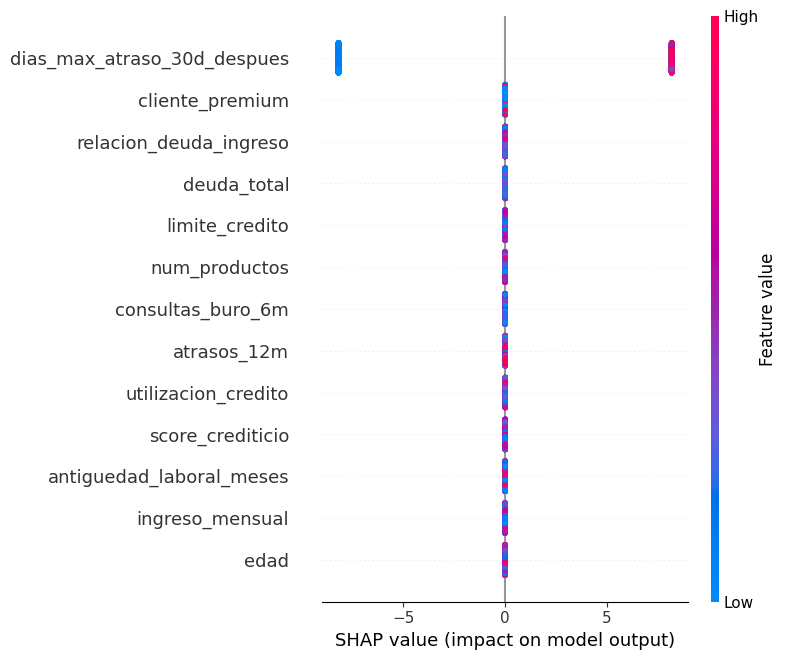

In [8]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

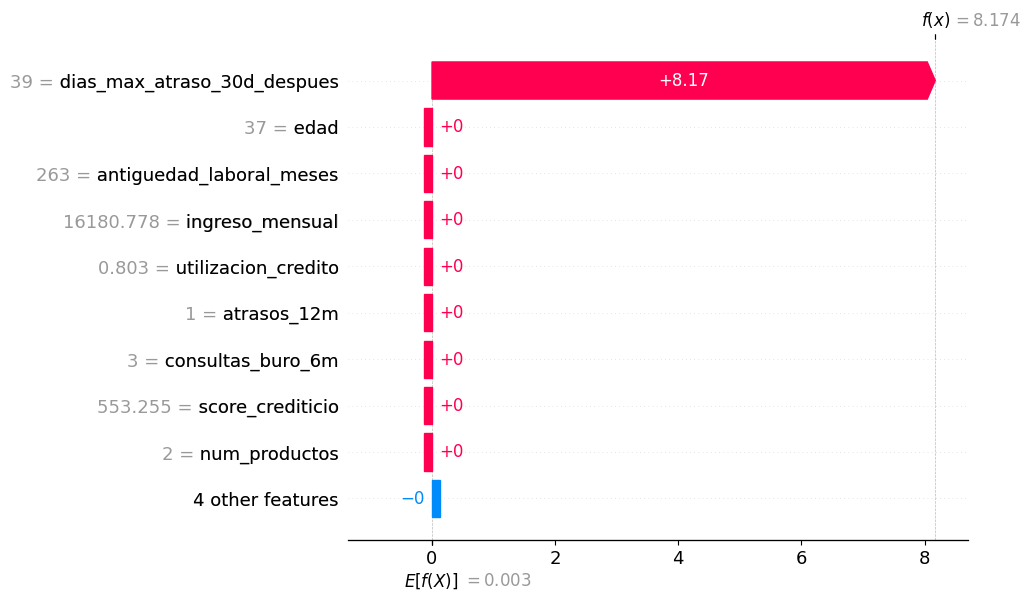

In [9]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

# **Análisis desde la perspectiva del negocio:**

In [17]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [18]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


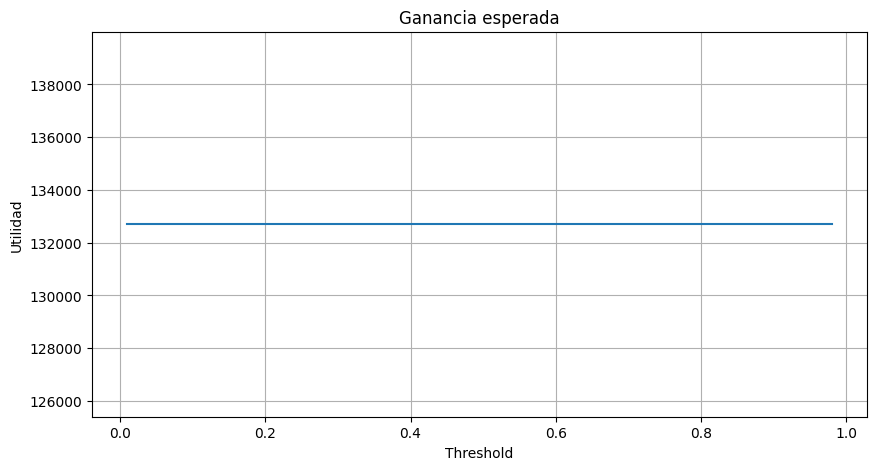

In [19]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [20]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [21]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


## **Matriz de Confusión**



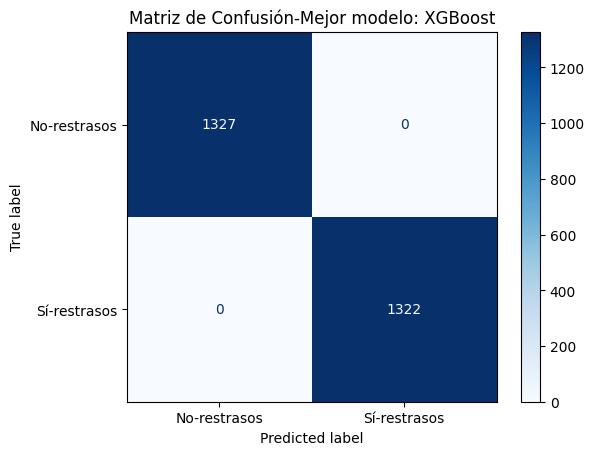

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

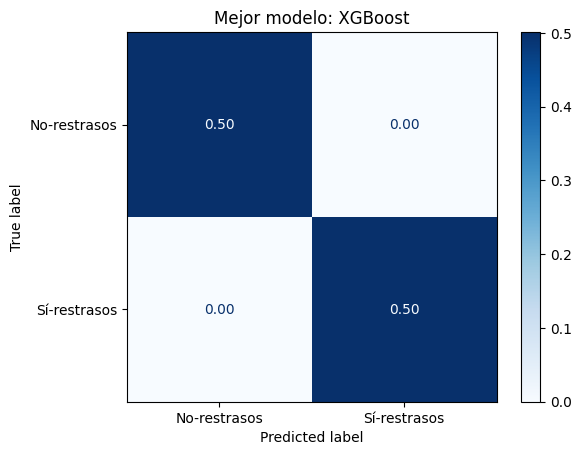

In [23]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

In [24]:
#Propuesta de código corregido (en la conclusión se explica la razón de las métricas usadas, así como los cambios realizados)
LEAK = ["dias_max_atraso_30d_despues"]
GANANCIA_BUENO, PERDIDA_DEFAULT = 100, -500

X = df.drop(columns=[target] + LEAK)
y = df[target]

# Split primero, estratificado (idealmente fuera de tiempo si hay fecha)
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RANDOM_STATE)

# Desbalanceo: pesos de clase en lugar de SMOTE (mantiene datos reales)
pw = (y_train == 0).sum() / (y_train == 1).sum()
modelos = {
    "DT": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
              class_weight="balanced", random_state=RANDOM_STATE),
    "RF": RandomForestClassifier(max_depth=8, min_samples_leaf=30,
              class_weight="balanced", random_state=RANDOM_STATE),
    "XGB": XGBClassifier(max_depth=3, n_estimators=300, learning_rate=0.05,
              scale_pos_weight=pw, eval_metric="aucpr", random_state=RANDOM_STATE),
}

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import CalibratedClassifierCV

def utilidad(y_true, y_prob, th):
    aprobado = y_prob < th
    return (np.where(np.asarray(y_true) == 0, GANANCIA_BUENO, PERDIDA_DEFAULT) * aprobado).mean()

res, probs_val = {}, {}
for n, m in modelos.items():
    m.fit(X_train, y_train)
    cal = CalibratedClassifierCV(m, method="isotonic", cv="prefit").fit(X_val, y_val)
    # (alternativa: calibrar con un tercer conjunto o con cv=5 sobre train)
    pt, pv = cal.predict_proba(X_train)[:, 1], cal.predict_proba(X_val)[:, 1]
    res[n] = dict(
        PR_AUC_train=average_precision_score(y_train, pt),
        PR_AUC_val=average_precision_score(y_val, pv),
        ROC_val=roc_auc_score(y_val, pv),
        util_val_th017=utilidad(y_val, pv, 1/6))
    probs_val[n] = (cal, pv)
print(pd.DataFrame(res).T)   # gap train-val => sobreentrenamiento

# Umbral elegido en VALIDACIÓN; reporte final en TEST (una sola vez)
mejor = "XGB"   # confirmar con la tabla anterior
cal, pv = probs_val[mejor]
ths = np.arange(0.02, 0.60, 0.01)
u_val = [utilidad(y_val, pv, t) for t in ths]
th_opt = ths[int(np.argmax(u_val))]

pt_test = cal.predict_proba(X_test)[:, 1]
for t in (0.5, th_opt):
    print(f"th={t:.2f}  utilidad/10,000 solicitudes: ${utilidad(y_test, pt_test, t)*10_000:,.0f}")
print("Tasa real de default:", y.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


     PR_AUC_train  PR_AUC_val   ROC_val  util_val_th017
DT       0.391343    0.420905  0.812682            53.4
RF       0.500943    0.491462  0.855059            56.2
XGB      0.677328    0.462916  0.823252            54.6
th=0.50  utilidad/10,000 solicitudes: $393,000
th=0.13  utilidad/10,000 solicitudes: $467,000
Tasa real de default: 0.1172


# **Inicia sección de Conclusiones Particulares**
Con la información presentada anteriormente, se puede concluir que **el modelo no puede desplegarse**. Esto debido a que en los resultados podemos observar un desempeño perfecto, sin embargo, un 100% de exactitud en el modelo nos da una señal de que hay algo roto.

En los datos tenemos la variable dias_max_atraso_30d_despues mide el máximo de días de atraso en los 30 días posteriores a la evaluación. Es prácticamente la variable objetivo escrita de otra forma, y no existe al momento de decidir si se otorga el crédito. La evidencia es la siguiente:


*   El árbol de decisión asigna importancia 1.0 a esa variable y 0.0 a todas las demás.
*   El gráfico SHAP es bimodal.
*   La matriz de confusión no tiene ningún error

También, en el código, SMOTE se aplicó antes de dividir en entrenamiento y prueba. El umbral se optimizó directamente sobre el conjunto de prueba, por lo que ya no es un conjunto independiente.

## **Errores conceptuales y metodológicos**

1.   La variable *dias_max_atraso_30d_despues* es posterior al evento, por lo que tiene un desempeño irreal. Se recomienda eliminarla.
2.   Se aplica SMOTE antes del split, esto ocasiona que train y test se "contaminen". Se recomienda dividir primero y aplicar SMOTE solo al entrenamiento.
3.   SMOTE sobre variables enteras y binarias como cliente_premium, num_productos, atrasos_12m; esto genera valores como 0.37 premium o 2.4 productos. Se recomienda usar SMOTENC o pesos de clase.
4.    Solo se evalúa los modelos con accuracy. Es una métrica engañosa porque los datos están desbalanceados, los errores no cuestan lo mismo (un falso negativo vs un falso positivo), depende de un umbral fijo (0.5). Se recomienda reportar utilidad esperada, PR-AUC, ROC-AUC, recall y presición de deudores, brier score.
5.    El conjunto de test se usa para tomar desiciones, por lo que no es una prueba honesta. Se recomienda realizar una validación cruzada, o una validación fuera de tiempo.
6.   Probabilidades saturadas. Como el modelo conocía la respuesta, sus probabilidades eran casi siempre 0 o 1. Con probabilidades así, cualquier umbral entre 0.01 y 0.98 aprueba exactamente a los mismos clientes y la utilidad es idéntica. Se recomienda eliminar la fuga y calibrar las probabilidades.
7.   Probabilidades no calibradas tras SMOTE. SMOTE llevó la muestra a 50/50. El modelo aprende entonces que la probabilidad base de incumplir es 50%, cuando en la realidad es 11.7%. Todas sus probabilidades quedan infladas. Se recomienda calibrar con datos sin remuestrear.
8.   Variable edad y sesgo de selección. La variable edad puede generar discriminación indirecta. Se recomienda eliminar la variable paar que no genere ruido.


## **Sub y sobreentrenamiento**
La comparación entre entrenamiento y prueba muestra una brecha de cero. Esto descartaría el sobreentrenamiento, pero aquí el diagnóstico es inválido porque ambos conjuntos comparten la misma fuga. Tampoco hay forma de descartar subentrenamiento, porque el modelo solo usa una variable. Se debe de repetir el diagnóstico con el pipeline corregido, comparando PR-AUC y utilidad en train, validación y prueba.

Con el código corregido, la métrica de referencia es la PR-AUC. Un modelo sin información tendría una PR-AUC igual a la tasa de incumplimiento, 0.117.

| Modelo | PR-AUC train | PR-AUC val | Brecha | Diagnóstico |
| :--- | :---: | ---: | ---: | ---: |
| Árbol (DT) | 0.391 | 0.421 | -0.030 | Sin sobreajuste; posible leve subajuste |
| Random Forest | 0.501 | 0.491 |  0.009 | Bien ajustado |
| XGBoost | 0.677 | 0.463 | 0.214 |	Sobreentrenamiento |

El árbol de decisión no sobreajusta, y es el candidato a subajuste. Random Forest es el más equilibrado. No hay subajuste severo en general. Con base en estas evidencias, se recomienda el Random Forest.

## **Impacto de la selección del umbral de clasificación**

La selección del umbral tiene un impacto económico mayor que la elección entre modelos. Con el Random Forest calibrado, la utilidad por cada 10,000 solicitudes es cerca de $391,000 con el umbral estándar de 0.50 (que aprueba al 96% de las solicitudes y detecta solo el 19% de los deudores), y de $504,000–$507,000 con umbrales entre 0.17 y 0.20, una mejora cercana a $115,000. Sin modelo, aprobar a todos produciría cerca de $297,000. El umbral teórico de equilibrio, coincide prácticamente con el óptimo empírico, y la utilidad se mantiene por encima del 98% del máximo para cualquier valor entre 0.11 y 0.25. Se recomienda operar con un umbral cercano a 0.17, rechazando a clientes con probabilidad de incumplimiento superior a 17%, y revisarlo periódicamente cuando cambien los costos o la tasa de incumplimiento.

## **Modelo recomendado**

Se recomienda desplegar el Random Forest (calibrado y con el umbral de aprobación en 0.17). Es el mejor de los tres en validación (PR-AUC 0.491, ROC 0.855, utilidad de $56.2 por solicitud) y el único sin sobreentrenamiento (brecha de 0.009 en PR-AUC); XGBoost sobreentrena (0.677 contra 0.463) y el árbol individual es el menos preciso y el más inestable.

Los cuatro factores principales son:
1. La utilización del crédito, con riesgo que se dispara por encima de 70% de uso (28% de incumplimiento).
2. Las consultas al buró en 6 meses, señal de búsqueda urgente de financiamiento (22% de incumplimiento con 5 o más consultas).
3. El score crediticio, que identifica al 20% de mayor riesgo.
4. La relación deuda/ingreso, que mide la capacidad de pago (24% de incumplimiento cuando supera 2.8 veces el ingreso mensual).

Variables como la edad, el segmento premium o el ingreso aportan prácticamente nada, por lo que edad puede retirarse.

### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

Durante esta actividad, el uso de un modelo de lenguaje (LLM) resultó de gran utilidad para interpretar los resultados y profundizar en el análisis de la información. También facilitó la realización de ajustes en el código: cuando surgían errores, la herramienta permitió encontrar soluciones con mayor rapidez, lo que redujo el tiempo dedicado a la depuración.

Sin embargo, es fundamental revisar con criterio la información que proporciona. Aunque la LLM entregue datos y explicaciones convincentes, el analista es el responsable de interpretarlos correctamente y de realizar los ajustes necesarios cuando los resultados no sean consistentes. Asimismo, conviene identificar cuándo la herramienta genera respuestas sesgadas o imprecisas por no contar con información suficiente, ya sea proporcionándole más contexto o contrastando sus conclusiones con los resultados reales.

En conclusión, la LLM es un excelente apoyo para agilizar el análisis y la depuración del código, pero no sustituye el juicio crítico del analista. Su mayor valor se obtiene al combinar la rapidez de la herramienta con la validación y la interpretación responsable de quien la utiliza.


### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**